# Results — task-aware vs task-agnostic compressor selection

Reads the latest `summary.csv` per dataset under `results/<ds>/<stamp>/`; Regenerate the inputs with `./scripts/run_all.sh`.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RESULTS = REPO_ROOT / "results"
FIGDIR = RESULTS / "figures"
FIGDIR.mkdir(exist_ok=True)
# Active portfolio: classification-capable datasets only. Every dataset
# carries BOTH a forecasting head (and a classification head — required so the
# task-aware vs task-agnostic comparison has > 1 task family on every
# dataset.
DATASETS = ["uci_har", "opportunity", "hydraulic", "beijing", "metro"]

def latest_summary(ds: str) -> Path | None:
    runs = sorted((RESULTS / ds).glob("*/summary.csv"))
    return runs[-1] if runs else None


frames = []
for ds in DATASETS:
    p = latest_summary(ds)
    if p is None:
        print(f"[warn] no summary for {ds}")
        continue
    df = pd.read_csv(p)
    df["dataset"] = ds
    df["run"] = p.parent.name
    frames.append(df)

# `summary_df` keeps ALL tasks. Cells that mix tasks read from it
# directly; cells with forecasting-shaped axes use `df_fc` below.
summary_df = pd.concat(frames, ignore_index=True)

# Unmodified snapshot of the raw concatenated summaries (keeps train_fold /
# eval_fold and every method), for cells that need the original frame before
# any reshaping below.
summary_df_raw = summary_df.copy()

# --- Normalisation contract ----------------------------------------------
# loss_tilde / storage_tilde / multi_obj come straight from summary.csv,
# computed by src/normalisation.py; 
ALPHA = 0.5  # headline storage weight — keep in sync with cfg.ALPHA

assert {"train_fold", "eval_fold"}.issubset(summary_df.columns), (
    "summary.csv is missing train_fold / eval_fold — re-run the pipeline "
    "with the K×K temporal-shift logic."
)
_required = {"loss_tilde", "storage_tilde", "multi_obj"}
assert _required.issubset(summary_df.columns), (
    f"summary.csv is missing {_required} — run scripts/renormalise_summary.py"
)

# --- Temporal-shift schema split -----------------------------------------
#   * `summary_df_full` — full K×K matrix: temporal-shift cells and
#     the `past` family (admissible below-diagonal cells).
#   * `summary_df`      — diagonal view (train_fold == eval_fold) with
#     eval_fold renamed to `fold`; used by every other cell.
summary_df_full = summary_df.copy()
summary_df = summary_df[summary_df["train_fold"] == summary_df["eval_fold"]].copy()
summary_df = summary_df.drop(columns=["train_fold"]).rename(columns={"eval_fold": "fold"})

# `df_fc` — forecasting-only view used by every cell whose summary axes
# are (target, horizon).
df_fc = summary_df[summary_df["task"] == "forecasting"].copy()

print(f"loaded {len(frames)} datasets · {len(summary_df)} rows total")
print(f"  forecasting:    {(summary_df['task'] == 'forecasting').sum():>5} rows  "
      f"({summary_df[summary_df['task'] == 'forecasting']['dataset'].nunique()} datasets)")
print(f"  classification: {(summary_df['task'] == 'classification').sum():>5} rows  "
      f"({summary_df[summary_df['task'] == 'classification']['dataset'].nunique()} datasets)")
print(f"  forecasting drill-down view df_fc has {len(df_fc)} rows")
print(f"folds per dataset:\n{summary_df.groupby('dataset')['fold'].nunique().to_string()}")
n_cells = summary_df_full.groupby("dataset").apply(
    lambda g: g.groupby(["train_fold", "eval_fold"]).ngroups
)
print(f"temporal-shift matrix cells per dataset:\n{n_cells.to_string()}")
df_fc.head()


loaded 5 datasets · 8800 rows total
  forecasting:     4575 rows  (5 datasets)
  classification:   845 rows  (5 datasets)
  forecasting drill-down view df_fc has 4575 rows
folds per dataset:
dataset
beijing        5
hydraulic      5
metro          5
opportunity    5
uci_har        5
temporal-shift matrix cells per dataset:
dataset
beijing        11
hydraulic      11
metro          11
opportunity    11
uci_har        11


,task,method,target,horizon,loss,nmse,nrmse,rmse,mse,n_samples,...,bytes_params,storage,cr,cr_bytes,cr_cells,loss_tilde,storage_tilde,multi_obj,dataset,run
0,forecasting,identity,body_acc_x,1.0,0.082764,0.082764,0.028146,0.056384,0.003179,109800,...,0,7908336,1.0,1.0,1.0,NaN,NaN,NaN,uci_har,20260901_212650
1,forecasting,identity,body_acc_x,12.0,0.622854,0.622854,0.077207,0.154668,0.023922,109800,...,0,7908336,1.0,1.0,1.0,NaN,NaN,NaN,uci_har,20260901_212650
2,forecasting,identity,body_acc_x,36.0,0.858402,0.858402,0.090606,0.181510,0.032946,109800,...,0,7908336,1.0,1.0,1.0,NaN,NaN,NaN,uci_har,20260901_212650
3,forecasting,identity,body_acc_y,1.0,0.115634,0.115634,0.018470,0.042873,0.001838,109800,...,0,7908336,1.0,1.0,1.0,NaN,NaN,NaN,uci_har,20260901_212650
4,forecasting,identity,body_acc_y,12.0,0.821502,0.821502,0.049221,0.114254,0.013054,109800,...,0,7908336,1.0,1.0,1.0,NaN,NaN,NaN,uci_har,20260901_212650


In [ ]:
# Fold-collapsed view used by plotting cells that need one number per
# (dataset, target, horizon, method) instead of per fold. Aggregations are
# mean-across-folds of already-normalised quantities.

_group = ["dataset", "target", "horizon", "method"]
_mean_cols = [
    "loss_tilde", "storage_tilde", "multi_obj",
    "nmse", "nrmse", "rmse", "mse", "cr", "cr_cells", "storage",
]
_mean_cols = [c for c in _mean_cols if c in df_fc.columns]
mean_df = df_fc.groupby(_group, as_index=False)[_mean_cols].mean()
_std_df = (
    df_fc.groupby(_group, as_index=False)[["multi_obj", "nmse"]]
    .std(ddof=0)
    .rename(columns={"multi_obj": "multi_obj_std", "nmse": "nmse_std"})
)
mean_df = mean_df.merge(_std_df, on=_group, how="left")
print(f"mean_df: {len(mean_df)} rows  (one per dataset × target × horizon × method)")



# -------------------------------------------------------------------------
# past_records — single source of truth for the `past` task family.
#
# Embargo: the block-disjoint K-fold layout in scripts/run_eval.py
# tiles the series into K + 1 = 6 disjoint blocks and assigns
#     train_k = block k     test_k = block k+1
# After the embargo trim on each test block's leading edge, the cells
# (k, j) with k > j are leakage-free iff k - j ≥ 2: when k = j + 1, both
# train_k and test_j sit inside the SAME B_{j+1} block (the embargo
# only trims test_j's leading edge, not its trailing one). So this
# helper drops k = j + 1 from the past pool — leaving 6 valid past cells
# out of the 10 below-diagonal candidates for K = 5. See López de Prado
# 2018 Ch. 7 for the purged / embargoed CV protocol.
# -------------------------------------------------------------------------
def past_records(df_full, value_col, lossless_methods=()):
    """Return (dataset, fold, method, task='past', subtask='', value_col) rows.

    `value_col` is averaged over (train_fold, target, horizon) within each
    (dataset, eval_fold, method) cell. Empty DataFrame if the K×K columns
    are missing or no rows match. Cells with train_fold - eval_fold == 1
    are excluded (embargo — see comment block above).
    """
    out_cols = ["dataset", "fold", "method", "task", "subtask", value_col]
    if "train_fold" not in df_full.columns or "eval_fold" not in df_full.columns:
        return pd.DataFrame(columns=out_cols)
    mask = (
        (df_full["task"] == "forecasting")
        & ((df_full["train_fold"] - df_full["eval_fold"]) >= 2)
        & (~df_full["method"].isin(set(lossless_methods)))
    )
    sub = df_full[mask]
    if sub.empty:
        return pd.DataFrame(columns=out_cols)
    out = (
        sub.groupby(["dataset", "eval_fold", "method"], as_index=False)[value_col]
        .mean()
        .rename(columns={"eval_fold": "fold"})
    )
    out["task"] = "past"
    out["subtask"] = ""
    return out[out_cols]


mean_df: 915 rows  (one per dataset × target × horizon × method)


## Price of generality — task-specific vs task-agnostic


In [4]:
# §4 — Price of Generality (PoG): task-specific C*_TS vs task-agnostic C*_TA.
#
# Definitions:
#
#   h_t(m, ds, k)   = mean over subtasks of loss_tilde   (per-cell scope)
#   S̃(m, ds, k)    = storage_tilde at (m, ds, k)
#   L_TA(m, ds, k)  = (1−α)·mean_t h_t + α·S̃            (α = storage weight)
#   L_Ft(m, ds, k)  = (1−α)·h_t + α·S̃
#   C*_TA(ds)       = argmin_m E_k[L_TA]                 (ONE pick per dataset)
#   C*_TS(ds, t)    = argmin_m E_k[L_Ft]
#   PoG_t(ds)       = E_k[L_Ft(C*_TA)] − E_k[L_Ft(C*_TS)] ≥ 0

WORKLOAD_TASKS = ["forecasting", "past", "classification", "aggregate_query"]
LOSSLESS_METHODS = {"gorilla", "identity"}
T = len(WORKLOAD_TASKS)          # 4 families (fc, past, cls, agg)
N_TYPES = 3                      # task-TYPES: fc{fwd+past}, cls, agg
MU_UNIFORM = 1.0 / N_TYPES

lossy = summary_df[~summary_df["method"].isin(LOSSLESS_METHODS)].copy()

# --- per-task aggregate loss h_t(m, ds, fold) -----------------------------
h_t = (
    lossy[lossy["task"].isin(["forecasting", "classification", "aggregate_query"])]
    .groupby(["dataset", "fold", "method", "task"], as_index=False)["loss_tilde"]
    .mean()
)
h_past = past_records(summary_df_full, value_col="loss_tilde",
                      lossless_methods=LOSSLESS_METHODS)
if not h_past.empty:
    h_t = pd.concat(
        [h_t, h_past[["dataset", "fold", "method", "task", "loss_tilde"]]],
        ignore_index=True,
    )

# --- global storage S̃(m, ds, fold) ----------------------------------------
s_tilde = (
    lossy.drop_duplicates(["dataset", "fold", "method"])
    [["dataset", "fold", "method", "storage_tilde"]]
)

# --- fold-level L table -----------------------------------------------------
h_pivot = (
    h_t.pivot_table(index=["dataset", "fold", "method"],
                    columns="task", values="loss_tilde", aggfunc="mean")
    .reset_index()
)
L_df = h_pivot.merge(s_tilde, on=["dataset", "fold", "method"], how="inner")
# skipna=False: L_TA is defined only on folds where every family exists
# (past is missing on the last two eval folds); the groupby mean below
# then averages over the defined folds only.

# The workload is THREE task-types, weighted equally —
# forecasting {forward + past} counts as ONE type (its two facets
# averaged), classification, and aggregate-query. This stops the
# forecasting direction being silently double-weighted (it has two
# metrics), and makes the triangle centroid the true headline
# (centred star). 
_fc_type = L_df[["forecasting", "past"]].mean(axis=1, skipna=False)
L_df["h_bar"] = (_fc_type + L_df["classification"]
                 + L_df["aggregate_query"]) / 3.0
L_df["L_TA"] = (1.0 - ALPHA) * L_df["h_bar"] + ALPHA * L_df["storage_tilde"]
for _t in WORKLOAD_TASKS:
    L_df[f"L_TS_{_t}"] = (1.0 - ALPHA) * L_df[_t] + ALPHA * L_df["storage_tilde"]
# combined forecasting task-TYPE (forward + past) = the 3-type forecasting specialist
L_df["L_TS_fctype"] = (1.0 - ALPHA) * _fc_type + ALPHA * L_df["storage_tilde"]

# --- argmin of the fold-averaged loss --------------------------------------
_val_cols = ["L_TA", "L_TS_fctype"] + [f"L_TS_{t}" for t in WORKLOAD_TASKS] + WORKLOAD_TASKS
mean_L = L_df.groupby(["dataset", "method"], as_index=False)[_val_cols].mean()

_ta_idx = mean_L.groupby("dataset")["L_TA"].idxmin()
C_TA_star = mean_L.loc[_ta_idx, ["dataset", "method"]].rename(
    columns={"method": "C_TA_star"}
)
_ft_parts = []
for _t in WORKLOAD_TASKS + ["fctype"]:
    _idx = mean_L.groupby("dataset")[f"L_TS_{_t}"].idxmin()
    _ft_parts.append(
        mean_L.loc[_idx, ["dataset", "method"]]
        .rename(columns={"method": "C_TS_star"})
        .assign(task=_t)
    )
C_TS_star = pd.concat(_ft_parts, ignore_index=True)

# --- Eq. (3.10): PoG on the fold-averaged L_Ft ------------------------------
L_mean_long = mean_L.melt(
    id_vars=["dataset", "method"],
    value_vars=[f"L_TS_{t}" for t in WORKLOAD_TASKS + ["fctype"]],
    var_name="task", value_name="L_Ft_mean",
)
L_mean_long["task"] = L_mean_long["task"].str.replace("L_TS_", "", regex=False)
L_at_TA = (
    L_mean_long.merge(C_TA_star, on="dataset")
    .query("method == C_TA_star")
    [["dataset", "task", "C_TA_star", "L_Ft_mean"]]
    .rename(columns={"L_Ft_mean": "L_at_TA"})
)
L_at_Ft = (
    L_mean_long.merge(C_TS_star, on=["dataset", "task"])
    .query("method == C_TS_star")
    [["dataset", "task", "C_TS_star", "L_Ft_mean"]]
    .rename(columns={"L_Ft_mean": "L_at_Ft"})
)
pog = L_at_TA.merge(L_at_Ft, on=["dataset", "task"])
pog["price_of_generality"] = pog["L_at_TA"] - pog["L_at_Ft"]
assert (pog["price_of_generality"] >= -1e-12).all(), "PoG must be ≥ 0"

# --- per-fold spread of the same fixed picks (support view) -----------------
L_fold_long = L_df.melt(
    id_vars=["dataset", "fold", "method"],
    value_vars=[f"L_TS_{t}" for t in WORKLOAD_TASKS],
    var_name="task", value_name="L_Ft",
).dropna(subset=["L_Ft"])
L_fold_long["task"] = L_fold_long["task"].str.replace("L_TS_", "", regex=False)
pog_folds = (
    L_fold_long.merge(C_TA_star, on="dataset").query("method == C_TA_star")
    [["dataset", "fold", "task", "L_Ft"]].rename(columns={"L_Ft": "L_at_TA"})
    .merge(
        L_fold_long.merge(C_TS_star, on=["dataset", "task"])
        .query("method == C_TS_star")
        [["dataset", "fold", "task", "L_Ft"]].rename(columns={"L_Ft": "L_at_Ft"}),
        on=["dataset", "fold", "task"],
    )
)
pog_folds["price_of_generality"] = pog_folds["L_at_TA"] - pog_folds["L_at_Ft"]

summary_pog = (
    pog_folds.groupby(["dataset", "task"])
    .agg(
        n_folds=("price_of_generality", "size"),
        mean_pog=("price_of_generality", "mean"),
        std_pog=("price_of_generality", "std"),
        max_pog=("price_of_generality", "max"),
        frac_pos=("price_of_generality", lambda s: float((s > 1e-9).mean())),
    )
    .reset_index()
    .sort_values(["dataset", "task"])
)

# Headline C*_TA per dataset 
C_TA_star_modal = C_TA_star.rename(columns={"C_TA_star": "modal_C_TA_star"})

print(f"L_TA  = (1−α)·mean over 3 task-types + α·S̃  "
      f"(α={ALPHA}, fc-type = mean(forecasting, past); μ=1/3 per type)")
print(f"L_Ft  = (1−α)·h_t + α·S̃           (one per task family)")
print(f"PoG_t = E_k[L_Ft(C*_TA)] − E_k[L_Ft(C*_TS)]  ≥ 0")
print(f"selection pool: {mean_L['method'].nunique()} lossy methods "
      f"({sorted(LOSSLESS_METHODS)} excluded)")
print(f"workload tasks: {WORKLOAD_TASKS}")
print()
print("C*_TA per dataset (argmin of fold-averaged L_TA):")
print(C_TA_star_modal.to_string(index=False))
print()
print("Price of generality per (dataset, task) — fold-mean "
      "and per-fold spread:")
display(pog[["dataset", "task", "C_TA_star", "C_TS_star",
             "price_of_generality"]].sort_values(["dataset", "task"]))
summary_pog


L_TA  = (1−α)·mean over 3 task-types + α·S̃  (α=0.5, fc-type = mean(forecasting, past); μ=1/3 per type)
L_Ft  = (1−α)·h_t + α·S̃           (one per task family)
PoG_t = E_k[L_Ft(C*_TA)] − E_k[L_Ft(C*_TS)]  ≥ 0
selection pool: 33 lossy methods (['gorilla', 'identity'] excluded)
workload tasks: ['forecasting', 'past', 'classification', 'aggregate_query']

C*_TA per dataset (argmin of fold-averaged L_TA):
    dataset modal_C_TA_star
    beijing         dct_cr8
  hydraulic   sim_piece_cr8
      metro   sim_piece_cr8
opportunity        lttb_cr8
    uci_har          ae_cr8

Price of generality per (dataset, task) — fold-mean and per-fold spread:


,dataset,task,C_TA_star,C_TS_star,price_of_generality
15,beijing,aggregate_query,dct_cr8,lttb_cr8,0.001386
10,beijing,classification,dct_cr8,dct_cr8,0.000000
20,beijing,fctype,dct_cr8,downsample_cr8,0.005783
0,beijing,forecasting,dct_cr8,downsample_cr8,0.006914
5,beijing,past,dct_cr8,downsample_cr8,0.004242
16,hydraulic,aggregate_query,sim_piece_cr8,dct_cr8,0.025881
11,hydraulic,classification,sim_piece_cr8,pca_cr6,0.155749
21,hydraulic,fctype,sim_piece_cr8,downsample_cr8,0.003033
1,hydraulic,forecasting,sim_piece_cr8,dct_cr8,0.001588
6,hydraulic,past,sim_piece_cr8,dct_cr8,0.002223


,dataset,task,n_folds,mean_pog,std_pog,max_pog,frac_pos
0,beijing,aggregate_query,5,0.001386,0.014847,0.017483,0.600000
1,beijing,classification,5,0.000000,0.000000,0.000000,0.000000
2,beijing,forecasting,5,0.006914,0.013288,0.021110,0.600000
3,beijing,past,3,0.004242,0.018658,0.025494,0.333333
4,hydraulic,aggregate_query,5,0.025881,0.046901,0.104617,0.600000
5,hydraulic,classification,5,0.155749,0.307236,0.494226,0.400000
6,hydraulic,forecasting,5,0.001588,0.012508,0.016478,0.600000
7,hydraulic,past,3,0.002223,0.008176,0.011198,0.666667
8,metro,aggregate_query,5,0.000000,0.000000,0.000000,0.000000
9,metro,classification,5,0.000000,0.000000,0.000000,0.000000


## Winner per (task, dataset)

The premise: different tasks pick different compressors. Heatmap rows =
tasks (`past`, forecasting horizons, `classification`,
`aggregate_query`), columns = datasets; each cell is the lossy compressor
minimising mean `multi_obj` (colour = family, size = CR). A monochrome
column ⇒ task-orthogonal ($C^{*}_{TS}=C^{*}_{TA}$); mixed ⇒ task-aware
leverage. Lossless excluded.


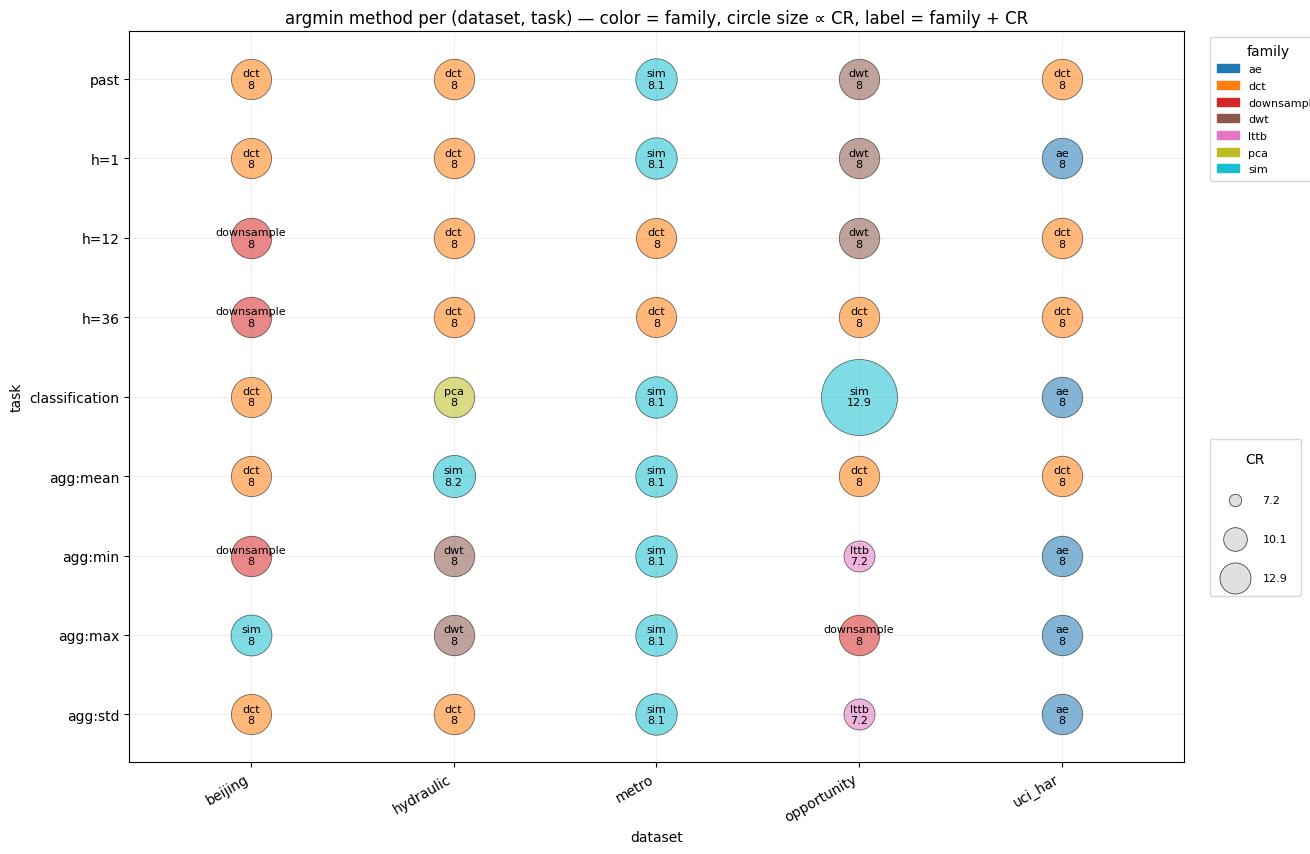

In [6]:
# §3 — Winner per task, per dataset.
#Lossless compressors (gorilla, identity) are excluded from the argmin.

LOSSLESS_METHODS_S7 = {"gorilla", "identity"}
_df_fc_lossy = df_fc[~df_fc["method"].isin(LOSSLESS_METHODS_S7)]
_summary_lossy = summary_df[~summary_df["method"].isin(LOSSLESS_METHODS_S7)]
_summary_full_lossy = summary_df_full[
    ~summary_df_full["method"].isin(LOSSLESS_METHODS_S7)
]

# --- Forecasting horizons (one row per horizon) ---
mo_per_dhm = (
    _df_fc_lossy.groupby(["dataset", "horizon", "method"])["multi_obj"]
    .mean()
    .reset_index()
)
idx = mo_per_dhm.groupby(["dataset", "horizon"])["multi_obj"].idxmin()
winners_dh = mo_per_dhm.loc[idx, ["dataset", "horizon", "method"]]
fcst_pivot = winners_dh.pivot(index="horizon", columns="dataset", values="method")
fcst_pivot = fcst_pivot.sort_index(ascending=True)
fcst_pivot.index = [f"h={int(h)}" for h in fcst_pivot.index]

# --- Past row ---
past_row_df = None
if {"train_fold", "eval_fold"}.issubset(_summary_full_lossy.columns):
    # Admissible past cells only: k − j ≥ 2 
    past_long = _summary_full_lossy[
        (_summary_full_lossy["train_fold"]
         - _summary_full_lossy["eval_fold"]) >= 2
    ]
    if not past_long.empty:
        mo_per_past = (
            past_long.groupby(["dataset", "method"])["multi_obj"]
            .mean()
            .reset_index()
        )
        idx_past = mo_per_past.groupby("dataset")["multi_obj"].idxmin()
        past_winners = mo_per_past.loc[idx_past].set_index("dataset")["method"]
        past_row_df = pd.Series(
            {ds: past_winners.get(ds, np.nan) for ds in fcst_pivot.columns},
            name="past",
        ).to_frame().T

# --- Classification row ---
cls_row_df = None
cls_rows = _summary_lossy[_summary_lossy["task"] == "classification"]
if not cls_rows.empty:
    mo_per_cls = (
        cls_rows.groupby(["dataset", "method"])["multi_obj"]
        .mean()
        .reset_index()
    )
    idx_cls = mo_per_cls.groupby("dataset")["multi_obj"].idxmin()
    cls_winners = mo_per_cls.loc[idx_cls].set_index("dataset")["method"]
    cls_row_df = pd.Series(
        {ds: cls_winners.get(ds, np.nan) for ds in fcst_pivot.columns},
        name="classification",
    ).to_frame().T


# --- Aggregate-query rows (one per agg ∈ {mean, max, min, std}) ---
agg_rows = []
_agg_src = _summary_lossy[_summary_lossy["task"] == "aggregate_query"]
if not _agg_src.empty and "agg" in _agg_src.columns:
    for _agg_name in ["mean", "min", "max", "std"]:
        _sub = _agg_src[_agg_src["agg"] == _agg_name]
        if _sub.empty:
            continue
        _mo_per = (
            _sub.groupby(["dataset", "method"])["multi_obj"]
            .mean().reset_index()
        )
        _idx_a = _mo_per.groupby("dataset")["multi_obj"].idxmin()
        _wins  = _mo_per.loc[_idx_a].set_index("dataset")["method"]
        _row = pd.Series(
            {ds: _wins.get(ds, np.nan) for ds in fcst_pivot.columns},
            name=f"agg:{_agg_name}",
        ).to_frame().T
        agg_rows.append(_row)

parts = []
if past_row_df is not None:
    parts.append(past_row_df)
parts.append(fcst_pivot)
if cls_row_df is not None:
    parts.append(cls_row_df)
parts.extend(agg_rows)
winner_pivot = pd.concat(parts)

# --- CR lookup per (dataset, method) ---
cr_lookup = summary_df.groupby(["dataset", "method"])["cr"].mean()


def plot_winner_heatmap(winner_pivot, cr_lookup, title):
    """Render a winner heatmap: rows = subtasks (or any axis), cols = datasets,
    cell = winning method shown as a coloured circle.
    
    - Colour = compressor family 
    - Circle area ∝ achieved byte-CR 
    - Cell label = "<family>_<CR>"
    """
    def _fmt_cr(cr):
        if not np.isfinite(cr):
            return "—"
        r = round(cr, 1)
        return f"{int(round(r))}" if abs(r - round(r)) < 1e-9 else f"{r:.1f}"

    def _family(m):
        return m.split("_")[0] if isinstance(m, str) else None

    cr_vals = []
    for task in winner_pivot.index:
        for ds in winner_pivot.columns:
            m = winner_pivot.at[task, ds]
            if isinstance(m, str) and (ds, m) in cr_lookup.index:
                cr_vals.append(float(cr_lookup.loc[(ds, m)]))
    cr_min = min(cr_vals) if cr_vals else 1.0
    cr_max = max(cr_vals) if cr_vals else 1.0

    def _size(cr):
        if cr_max == cr_min:
            return 1500
        t = (cr - cr_min) / (cr_max - cr_min)
        return 500 + t * 2500

    def _legend_size(cr):
        if cr_max == cr_min:
            return 250
        t = (cr - cr_min) / (cr_max - cr_min)
        return 80 + t * 420

    families_present = sorted({
        _family(m) for m in winner_pivot.values.ravel() if isinstance(m, str)
    })
    cmap = plt.cm.tab10
    denom = max(1, len(families_present) - 1)
    fam_to_color = {f: cmap(i / denom) for i, f in enumerate(families_present)}

    n_rows = len(winner_pivot.index)
    n_cols = len(winner_pivot.columns)
    fig, ax = plt.subplots(figsize=(2.2 + 2.2 * n_cols, 1.0 + 0.85 * n_rows))

    for i, task in enumerate(winner_pivot.index):
        for j, ds in enumerate(winner_pivot.columns):
            m = winner_pivot.at[task, ds]
            if not isinstance(m, str):
                continue
            cr = cr_lookup.get((ds, m), np.nan)
            family = _family(m)
            ax.scatter(
                j, i,
                s=_size(cr) if np.isfinite(cr) else 800,
                c=[fam_to_color[family]],
                edgecolors="black", linewidths=0.6, alpha=0.55, zorder=2,
            )
            label = f"{family}\n{_fmt_cr(cr)}"
            ax.text(j, i, label, ha="center", va="center",
                    fontsize=8, color="black", zorder=3)

    ax.set_xticks(range(n_cols))
    ax.set_xticklabels(winner_pivot.columns, rotation=30, ha="right")
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(winner_pivot.index)
    ax.set_xlim(-0.6, n_cols - 0.4)
    ax.set_ylim(-0.6, n_rows - 0.4)
    ax.invert_yaxis()
    ax.grid(True, which="major", alpha=0.2, zorder=0)
    ax.set_xlabel("dataset")
    ax.set_ylabel("task")
    ax.set_title(title)

    from matplotlib.patches import Patch
    fam_handles = [Patch(color=fam_to_color[f], label=f) for f in families_present]

    cr_mid = (cr_min + cr_max) / 2.0
    size_levels = [cr_min, cr_mid, cr_max]
    seen = set()
    size_levels_unique = []
    for v in size_levels:
        key = round(v, 2)
        if key in seen:
            continue
        seen.add(key)
        size_levels_unique.append(v)

    size_handles = [
        plt.scatter([], [], s=_legend_size(v), c="lightgrey",
                    edgecolors="black", linewidths=0.6, alpha=0.7,
                    label=_fmt_cr(v))
        for v in size_levels_unique
    ]

    leg1 = ax.legend(handles=fam_handles, bbox_to_anchor=(1.02, 1),
                     loc="upper left", fontsize=8, title="family",
                     frameon=True, borderpad=0.6, labelspacing=0.6)
    ax.add_artist(leg1)
    ax.legend(
        handles=size_handles, bbox_to_anchor=(1.02, 0.45),
        loc="upper left", fontsize=8, title="CR",
        labelspacing=2.6, borderpad=1.2, handletextpad=1.5,
        frameon=True,
    )

    plt.tight_layout()
    plt.show()


plot_winner_heatmap(
    winner_pivot, cr_lookup,
    title="argmin method per (dataset, task) — color = family, "
          "circle size ∝ CR, label = family + CR",
)


## Headline — per-subtask winners + C*_TA

§3's winner heatmap with one extra row: the task-agnostic pick
$C^{*}_{TA}$ per dataset (from §4's `C_TA_star_modal`). Where the
$C^{*}_{TA}$ row matches the subtask rows the agnostic rule is free;
where it disagrees, those subtasks pay the price of generality.


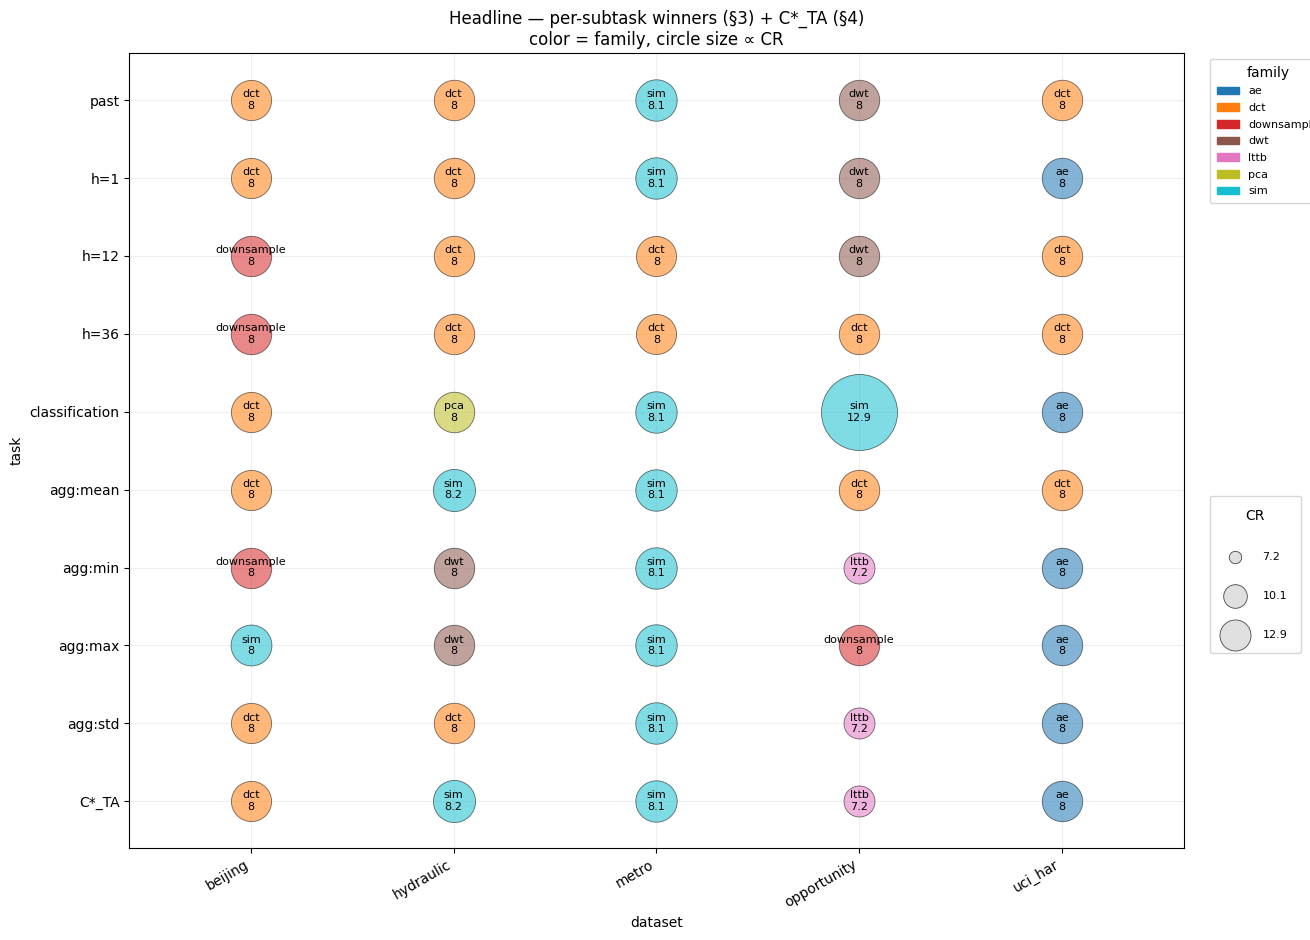

In [7]:
# §5 — Headline heatmap: per-subtask winners + the task-agnostic

assert "winner_pivot" in dir(), (
    "run §3 first — `winner_pivot` not defined"
)
assert "plot_winner_heatmap" in dir(), (
    "run §3 first — `plot_winner_heatmap` not defined"
)
assert "C_TA_star_modal" in dir(), (
    "run §4 first — `C_TA_star_modal` not defined"
)

# Build the C*_TA row from §4's Eq.-3.7 pick. reindex on winner_pivot.columns
# so the column order matches §3 and any missing dataset becomes NaN.
_ta_map = dict(zip(C_TA_star_modal["dataset"],
                   C_TA_star_modal["modal_C_TA_star"]))
_ta_row = (
    pd.Series({ds: _ta_map.get(ds, np.nan) for ds in winner_pivot.columns},
              name="C*_TA")
    .to_frame().T
)

winner_pivot_full = pd.concat([winner_pivot, _ta_row])

plot_winner_heatmap(
    winner_pivot_full, cr_lookup,
    title="Headline — per-subtask winners (§3) + C*_TA (§4)\n"
          "color = family, circle size ∝ CR",
)


In [8]:
# §5b — Headline as a table

assert "winner_pivot_full" in dir(), (
    "run §5 (headline heatmap) first — `winner_pivot_full` not defined"
)

# Methods only — no CR appendix; the suffix already encodes the target CR.
headline_table = winner_pivot_full.copy()
headline_table = headline_table.where(headline_table.notna(), "—")

print("§5 — Headline as a table (method names only):")
display(headline_table)


# --- LaTeX rendering --------------------------------------------------
def _tex_underscore(s):
    """Escape underscores for LaTeX text mode."""
    return str(s).replace("_", r"\_")


def _tex_cell(s):
    if not isinstance(s, str) or s == "—":
        return "---"
    if "_cr" in s:  # drop the redundant "cr", keep the "_": family_crN -> family_N
        return "\\texttt{" + _tex_underscore(s.replace("_cr", "_")) + "}"
    return f"\\texttt{{{_tex_underscore(s)}}}"


_tex_table = headline_table.map(_tex_cell)
_tex_table.columns = [_tex_underscore(c) for c in _tex_table.columns]
_tex_table.index = [_tex_underscore(i) for i in _tex_table.index]
_tex_table.index.name = "subtask"

latex_str = _tex_table.to_latex(
    escape=False,
    column_format="l" + "l" * len(_tex_table.columns),
    bold_rows=False,
    caption=(
        "Headline --- per-subtask winning compressor (one row per "
        "subtask), plus the task-agnostic pick (Eq.~3.7) "
        "$C^{*}_{TA}$ (bottom row) per dataset. Each cell shows the winning "
        "\\texttt{family} and its target CR \\texttt{N} "
        "(registry name \\texttt{family\\_crN})."
    ),
    label="tab:headline_winners",
)

# Inject \centering + \footnotesize so the table fits in a single
# thesis-column page width. pandas' to_latex emits the wrapper but no
# font-size hint; we splice it in just after \begin{table}.
if "\\begin{table}" in latex_str and "\\footnotesize" not in latex_str:
    latex_str = latex_str.replace(
        "\\begin{table}",
        "\\begin{table}\n\\centering\n\\footnotesize",
        1,
    )

print("\n--- LaTeX (paste-ready) ---\n")
print(latex_str)


§5 — Headline as a table (method names only):


,beijing,hydraulic,metro,opportunity,uci_har
past,dct_cr8,dct_cr8,sim_piece_cr8,dwt_cr8,dct_cr8
h=1,dct_cr8,dct_cr8,sim_piece_cr8,dwt_cr8,ae_cr8
h=12,downsample_cr8,dct_cr8,dct_cr8,dwt_cr8,dct_cr8
h=36,downsample_cr8,dct_cr8,dct_cr8,dct_cr8,dct_cr8
classification,dct_cr8,pca_cr6,sim_piece_cr8,sim_piece_cr8,ae_cr8
agg:mean,dct_cr8,sim_piece_cr8,sim_piece_cr8,dct_cr8,dct_cr8
agg:min,downsample_cr8,dwt_cr8,sim_piece_cr8,lttb_cr8,ae_cr8
agg:max,sim_piece_cr8,dwt_cr8,sim_piece_cr8,downsample_cr8,ae_cr8
agg:std,dct_cr8,dct_cr8,sim_piece_cr8,lttb_cr8,ae_cr8
C*_TA,dct_cr8,sim_piece_cr8,sim_piece_cr8,lttb_cr8,ae_cr8



--- LaTeX (paste-ready) ---

\begin{table}
\centering
\footnotesize
\caption{Headline --- per-subtask winning compressor (one row per subtask), plus the task-agnostic pick (Eq.~3.7) $C^{*}_{TA}$ (bottom row) per dataset. Each cell shows the winning \texttt{family} and its target CR \texttt{N} (registry name \texttt{family\_crN}).}
\label{tab:headline_winners}
\begin{tabular}{llllll}
\toprule
 & beijing & hydraulic & metro & opportunity & uci\_har \\
subtask &  &  &  &  &  \\
\midrule
past & \texttt{dct\_8} & \texttt{dct\_8} & \texttt{sim\_piece\_8} & \texttt{dwt\_8} & \texttt{dct\_8} \\
h=1 & \texttt{dct\_8} & \texttt{dct\_8} & \texttt{sim\_piece\_8} & \texttt{dwt\_8} & \texttt{ae\_8} \\
h=12 & \texttt{downsample\_8} & \texttt{dct\_8} & \texttt{dct\_8} & \texttt{dwt\_8} & \texttt{dct\_8} \\
h=36 & \texttt{downsample\_8} & \texttt{dct\_8} & \texttt{dct\_8} & \texttt{dct\_8} & \texttt{dct\_8} \\
classification & \texttt{dct\_8} & \texttt{pca\_6} & \texttt{sim\_piece\_8} & \texttt{sim\_p

## Result tables as LaTeX

Regenerates `tab:cost` and `tab:pog` as paste-ready LaTeX from the already-computed `mean_L` and `pog`.


In [9]:
# §5c — result tables as LaTeX.

_WT = ["forecasting", "past", "classification", "aggregate_query"]
_DISPLAY = {"uci_har": "UCI HAR","opportunity": "OPPORTUNITY",
            "hydraulic": "Hydraulic", "beijing": "Beijing", "metro": "Metro"}
_ORDER = [d for d in ["uci_har", "opportunity",
          "hydraulic", "beijing", "metro"] if d in set(DATASETS)]
_RULE = {"forecasting": "forecast", "past": "past",
         "classification": "classif.", "aggregate_query": "aggregate"}
_SPEC = ["fctype", "classification", "aggregate_query"]
_RULE_SPEC = {"fctype": "forecast", "classification": "classif.",
              "aggregate_query": "aggregate"}


def _tt(m):
    s = str(m)
    if "_cr" in s:  # drop redundant "cr", keep the "_": family_crN -> family_N
        s = s.replace("_cr", "_")
    return "\\texttt{" + s.replace("_", "\\_") + "}"


# ---- tab:cost (worst-matched PER-SUBTASK specialist; past excluded) -------
# The worst single-subtask specialist (a per-subtask winner of tab:winners,
# 'past' excluded) and its excess  WORKLOAD loss L_TA (from §4 mean_L) over C*_TA. 
_ABBRc = {"beijing": "BE", "hydraulic": "HY", "metro": "ME",
          "opportunity": "OP", "uci_har": "UC"}
_SUBLABc = {"h=1": "$h\\!=\\!1$", "h=12": "$h\\!=\\!12$", "h=36": "$h\\!=\\!36$",
            "classification": "classif.", "agg:mean": "agg:mean",
            "agg:min": "agg:min", "agg:max": "agg:max", "agg:std": "agg:std"}
_lossyC = summary_df[~summary_df["method"].isin(LOSSLESS_METHODS)]
_storC = _lossyC.drop_duplicates(["dataset", "fold", "method"])[
    ["dataset", "fold", "method", "storage_tilde"]]


def _scalC(sub):
    m = sub.merge(_storC, on=["dataset", "fold", "method"], how="inner")
    m["L"] = (1 - ALPHA) * m["loss_tilde"] + ALPHA * m["storage_tilde"]
    return m


_wrows = []
_fcW = (_lossyC[_lossyC["task"] == "forecasting"]
        .groupby(["dataset", "fold", "method", "horizon"], as_index=False)["loss_tilde"].mean())
for (d, h, m), v in _scalC(_fcW).groupby(["dataset", "horizon", "method"])["L"].mean().items():
    _wrows.append((d, f"h={int(h)}", m, v))
_clW = _lossyC[_lossyC["task"] == "classification"][["dataset", "fold", "method", "loss_tilde"]]
for (d, m), v in _scalC(_clW).groupby(["dataset", "method"])["L"].mean().items():
    _wrows.append((d, "classification", m, v))
_agW = _lossyC[_lossyC["task"] == "aggregate_query"][["dataset", "fold", "method", "agg", "loss_tilde"]]
for (d, a, m), v in _scalC(_agW).groupby(["dataset", "agg", "method"])["L"].mean().items():
    _wrows.append((d, f"agg:{a}", m, v))
_LsubC = pd.DataFrame(_wrows, columns=["dataset", "subtask", "method", "Lbar"])
_winC = (_LsubC.loc[_LsubC.groupby(["dataset", "subtask"])["Lbar"].idxmin()]
         .set_index(["dataset", "subtask"])["method"])
_ltaof = mean_L.set_index(["dataset", "method"])["L_TA"]
_ctaC = mean_L.loc[mean_L.groupby("dataset")["L_TA"].idxmin()].set_index("dataset")
_SUBORD = ["h=1", "h=12", "h=36", "classification",
           "agg:mean", "agg:min", "agg:max", "agg:std"]  # fixed tie-break order
_cost = []
for ds in _ORDER:
    tam, ta = _ctaC.loc[ds, "method"], float(_ctaC.loc[ds, "L_TA"])
    worst = None
    for u in _SUBORD:
        if (ds, u) not in _winC.index:
            continue
        m = _winC[(ds, u)]
        w = float(_ltaof[(ds, m)])
        if worst is None or w > worst[0]:
            worst = (w, u, m)
    lw, wu, wm = worst
    _cost.append(dict(dataset=ds, C_TA=tam, sub=wu, pick=wm, dL=lw - ta,
                      excess=100.0 * (lw - ta) / ta if ta > 0 else 0.0))
cost_df = pd.DataFrame(_cost).sort_values("excess", ascending=False)
print("Cost of mis-specialisation (per-subtask specialist, past excluded):")
print(cost_df.round(3).to_string(index=False))
_crows = []
for r in cost_df.itertuples():
    _crows.append("    " + _ABBRc[r.dataset] + " & " + _tt(r.C_TA) + " & "
                  + _tt(r.pick) + "\\ (" + _SUBLABc[r.sub] + ") & $"
                  + format(r.dL, ".2f") + "$ & $" + format(r.excess, "+.0f") + "\\%$ \\\\")
cost_tex = ("\\begin{tabular}{lllcc}\n    \\toprule\n    Dataset & $C^{*}_{\\mathrm{TA}}$ "
            "& worst subtask specialist & $\\Delta L$ & excess \\\\\n    \\midrule\n"
            + "\n".join(_crows) + "\n    \\bottomrule\n  \\end{tabular}")
print("\n--- LaTeX tab:cost (per-subtask) ---\n")
print(cost_tex)


# ---- tab:pog (price of generality per (dataset, subtask)) -----------------
_ABBR = {"beijing": "BE", "hydraulic": "HY", "metro": "ME",
         "opportunity": "OP", "uci_har": "UC"}
_COLS = [d for d in ["beijing", "hydraulic", "metro", "opportunity", "uci_har"]
         if d in set(DATASETS)]
_C_TA = dict(zip(C_TA_star["dataset"], C_TA_star["C_TA_star"]))
_lossy = summary_df[~summary_df["method"].isin(LOSSLESS_METHODS)]
_stor = _lossy.drop_duplicates(["dataset", "fold", "method"])[
    ["dataset", "fold", "method", "storage_tilde"]]


def _scal_mean(sub):
    """Fold-mean of L = (1-ALPHA)*loss_tilde + ALPHA*storage_tilde per method."""
    m = sub.merge(_stor, on=["dataset", "fold", "method"], how="inner")
    m["L"] = (1 - ALPHA) * m["loss_tilde"] + ALPHA * m["storage_tilde"]
    return m


_sub = []  # (dataset, subtask, method, Lbar)
_fc = (_lossy[_lossy["task"] == "forecasting"]
       .groupby(["dataset", "fold", "method", "horizon"], as_index=False)["loss_tilde"].mean())
for (d, h, m), v in _scal_mean(_fc).groupby(["dataset", "horizon", "method"])["L"].mean().items():
    _sub.append((d, f"$h={int(h)}$", m, v))
_past = past_records(summary_df_full, "loss_tilde", LOSSLESS_METHODS)[
    ["dataset", "fold", "method", "loss_tilde"]]
for (d, m), v in _scal_mean(_past).groupby(["dataset", "method"])["L"].mean().items():
    _sub.append((d, "past", m, v))
_cls = _lossy[_lossy["task"] == "classification"][["dataset", "fold", "method", "loss_tilde"]]
for (d, m), v in _scal_mean(_cls).groupby(["dataset", "method"])["L"].mean().items():
    _sub.append((d, "classification", m, v))
_agg = _lossy[_lossy["task"] == "aggregate_query"][
    ["dataset", "fold", "method", "agg", "loss_tilde"]]
for (d, a, m), v in _scal_mean(_agg).groupby(["dataset", "agg", "method"])["L"].mean().items():
    _sub.append((d, a, m, v))
_Lsub = pd.DataFrame(_sub, columns=["dataset", "subtask", "method", "Lbar"])


def _pog_sub(g):
    row = g.loc[g["method"] == _C_TA[g.name[0]], "Lbar"]
    return np.nan if row.empty else 100.0 * (row.iloc[0] - g["Lbar"].min())


_pogsub = (_Lsub.groupby(["dataset", "subtask"]).apply(_pog_sub, include_groups=False)
           .unstack("dataset").rename(columns=_ABBR))
_pogsub = _pogsub[[_ABBR[d] for d in _COLS]]
_FC_ROWS = ["past", "$h=1$", "$h=12$", "$h=36$", "classification"]
_AGG_ROWS = ["mean", "min", "max", "std"]
_pogsub = _pogsub.reindex([r for r in _FC_ROWS + _AGG_ROWS if r in _pogsub.index])
print("Price of generality per (dataset, subtask) — % of the scalarised-loss "
      "gap to the per-subtask best compressor:")
print(_pogsub.round(1).to_string())

# --- LaTeX: two side-by-side tabulars (forecasting+classification | aggregate)
_gmax = _pogsub.max().max()  # bold the single largest PoG


def _fmt(x):
    if pd.isna(x):
        return "--"
    s = f"{x:.1f}"
    return f"\\textbf{{{s}}}" if abs(x - _gmax) < 1e-9 else s


def _tabular(rows):
    cols = list(_pogsub.columns)
    head = "subtask & " + " & ".join(cols) + " \\\\"
    body = [r + " & " + " & ".join(_fmt(_pogsub.loc[r, c]) for c in cols) + " \\\\"
            for r in rows if r in _pogsub.index]
    return ("\\begin{tabular}{l" + "c" * len(cols) + "}\n\\toprule\n"
            + head + "\n\\midrule\n" + "\n".join(body)
            + "\n\\bottomrule\n\\end{tabular}")


pog_tex = _tabular(_FC_ROWS) + "\n\\qquad\n" + _tabular(_AGG_ROWS)
print("\n--- LaTeX tab:pog (subtask x dataset) ---\n")
print(pog_tex)


Cost of mis-specialisation (per-subtask specialist, past excluded):
    dataset          C_TA            sub          pick    dL   excess
      metro sim_piece_cr8           h=12       dct_cr8 0.160 1166.143
  hydraulic sim_piece_cr8 classification       pca_cr6 0.255  401.026
    beijing       dct_cr8        agg:max sim_piece_cr8 0.090   87.874
    uci_har        ae_cr8           h=12       dct_cr8 0.036   48.985
opportunity      lttb_cr8 classification sim_piece_cr8 0.081   47.437

--- LaTeX tab:cost (per-subtask) ---

\begin{tabular}{lllcc}
    \toprule
    Dataset & $C^{*}_{\mathrm{TA}}$ & worst subtask specialist & $\Delta L$ & excess \\
    \midrule
    ME & \texttt{sim\_piece\_8} & \texttt{dct\_8}\ ($h\!=\!12$) & $0.16$ & $+1166\%$ \\
    HY & \texttt{sim\_piece\_8} & \texttt{pca\_6}\ (classif.) & $0.26$ & $+401\%$ \\
    BE & \texttt{dct\_8} & \texttt{sim\_piece\_8}\ (agg:max) & $0.09$ & $+88\%$ \\
    UC & \texttt{ae\_8} & \texttt{dct\_8}\ ($h\!=\!12$) & $0.04$ & $+49\%$ \\
  

## Policy-space Pareto

In [10]:
# §10 setup — pymoo classes and (alpha, mu) helpers.
from pymoo.core.problem import ElementwiseProblem
from pymoo.decomposition.weighted_sum import WeightedSum
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
from matplotlib.tri import Triangulation
import warnings as _warnings
_warnings.filterwarnings("ignore", message=".*not compatible with tight_layout.*")
# ^ ternary axes use axis("off") + fixed aspect; tight_layout warns but the
#   warning is cosmetic (it nudges figure margins, NOT data coordinates —
#   the headline star is drawn in triangle data-coords and is unaffected).

# --- Layer 1 — formal multi-objective problem --
class TaskAgnosticCompressorChoice(ElementwiseProblem):
    """
    Discrete M-objective problem:
        F(C) = [l_tilde_1(C), ..., l_tilde_{M-1}(C), s_tilde(C)],   C in {0..K-1}
    All objectives minimised. Cited verbatim in the Problem Formulation chapter.
    """
    def __init__(self, F_table):
        F_table = np.asarray(F_table, dtype=float)
        K, M = F_table.shape
        super().__init__(n_var=1, n_obj=M, xl=0, xu=K - 1, vtype=int)
        self.F_table = F_table

    def _evaluate(self, x, out, *args, **kwargs):
        out["F"] = self.F_table[int(x[0])]


def pareto_front_indices(F_table):
    """Non-dominated indices. K small -> no search needed."""
    return NonDominatedSorting().do(np.asarray(F_table, dtype=float),
                                    only_non_dominated_front=True)


# --- Layer 2 — nested (alpha, mu) scalarisation -----------------------------
def lambda_from_alpha_mu(alpha, mu, tol=1e-9):
    """Return lam = ((1 - alpha) * mu, alpha) — alpha is the STORAGE weight."""
    mu = np.asarray(mu, dtype=float)
    assert (mu >= -tol).all() and abs(mu.sum() - 1.0) < tol, \
        f"mu must lie on the simplex (sum={mu.sum():.6f})"
    assert -tol <= alpha <= 1.0 + tol, f"alpha must be in [0,1] (got {alpha})"
    return np.concatenate([(1.0 - alpha) * mu, [alpha]])


# Barycentric headline point on the merged triangle. The
# workload is three EQUAL task-types — forecasting {forward+past},
# classification, aggregate_query — so the headline (uniform over the
# three types) is the triangle CENTROID. The policy plots mark it with
# a star.
MU_HEADLINE_MERGED = np.array([1.0/3, 1.0/3, 1.0/3])


def task_agnostic_loss(F_table, alpha, mu):
    """L_TA(C; alpha, mu) for every compressor C. Returns shape (K,)."""
    lam = lambda_from_alpha_mu(alpha, mu)
    return WeightedSum().do(F=np.asarray(F_table, dtype=float), weights=lam)


def task_agnostic_argmin(F_table, alpha, mu):
    """(winner_index, full L_TA vector) at (alpha, mu)."""
    L = task_agnostic_loss(F_table, alpha, mu)
    return int(np.argmin(L)), L


# --- Layer 3 — policy-space sweeps -----------------------------------------
def policy_ternary_M4(F_table, alpha, n=60):
    """
    At fixed alpha, sample the mu-triangle (Delta^2 over the 3 swept
    task vertices) and return (barycentric 2D points, winner index,
    L_TA at winner) per point. M = 4: the three vertices are (forecasting+past),
    classification, aggregate_query.
    """
    K, M = np.asarray(F_table).shape
    assert M == 4, "requires a 3-family merged triangle (3 tasks + storage)"
    pts, winners, l_at = [], [], []
    for i in range(n + 1):
        for j in range(n + 1 - i):
            k = n - i - j
            mu = np.array([i, j, k]) / n
            idx, L = task_agnostic_argmin(F_table, alpha, mu)
            x = j + k / 2.0
            y = (np.sqrt(3) / 2) * k
            pts.append((x, y)); winners.append(idx); l_at.append(L[idx])
    return np.array(pts), np.array(winners), np.array(l_at)


def gap_ternary_M4(F_table, alpha, n=60):
    """
    Excess loss of the task-agnostic-policy compressor C_TA(alpha)
    (the argmin at mu = uniform over ALL task families) versus the
    per-cell oracle at every mu on the merged 3-family triangle.
    """
    K, M = np.asarray(F_table).shape
    assert M == 4, "requires a 3-family merged triangle (3 tasks + storage)"
    mu_uniform = MU_HEADLINE_MERGED  # three-type headline: centroid of the merged triangle
    c_ta, _ = task_agnostic_argmin(F_table, alpha, mu_uniform)
    pts, gaps = [], []
    for i in range(n + 1):
        for j in range(n + 1 - i):
            k = n - i - j
            mu = np.array([i, j, k]) / n
            lam = lambda_from_alpha_mu(alpha, mu)
            L_all = np.asarray(F_table) @ lam
            gaps.append(L_all[c_ta] - L_all.min())
            pts.append((j + k / 2.0, (np.sqrt(3) / 2) * k))
    return np.array(pts), np.array(gaps), c_ta



uci_har

[uci_har] F-table (32, 4)  task_labels=['forecasting', 'classification', 'aggregate_query', 'storage']
[uci_har] Pareto-optimal compressors (18/32): ['ae_cr3', 'ae_cr4', 'ae_cr6', 'ae_cr8', 'dct_cr2', 'dct_cr3', 'dct_cr6', 'dct_cr8', 'downsample_cr2', 'downsample_cr3', 'downsample_cr4', 'downsample_cr8', 'lttb_cr4', 'sim_piece_cr2', 'sim_piece_cr3', 'sim_piece_cr4', 'sim_piece_cr6', 'sim_piece_cr8']


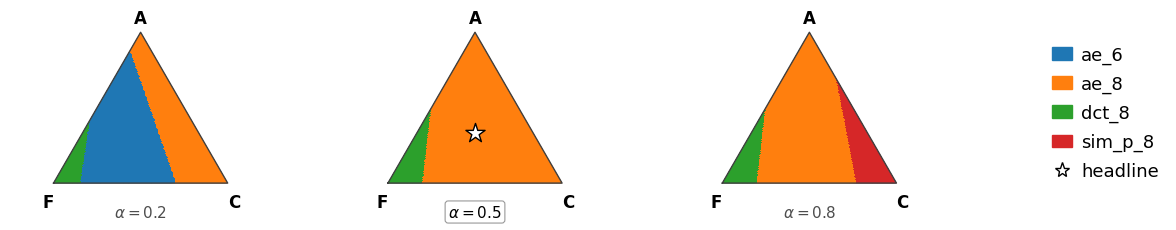

opportunity

[opportunity] F-table (32, 4)  task_labels=['forecasting', 'classification', 'aggregate_query', 'storage']
[opportunity] Pareto-optimal compressors (23/32): ['ae_cr8', 'dct_cr2', 'dct_cr3', 'dct_cr4', 'dct_cr6', 'downsample_cr2', 'downsample_cr3', 'downsample_cr4', 'downsample_cr6', 'downsample_cr8', 'dwt_cr2', 'dwt_cr8', 'lttb_cr2', 'lttb_cr3', 'lttb_cr4', 'lttb_cr6', 'lttb_cr8', 'pca_cr8', 'sim_piece_cr2', 'sim_piece_cr3', 'sim_piece_cr4', 'sim_piece_cr6', 'sim_piece_cr8']


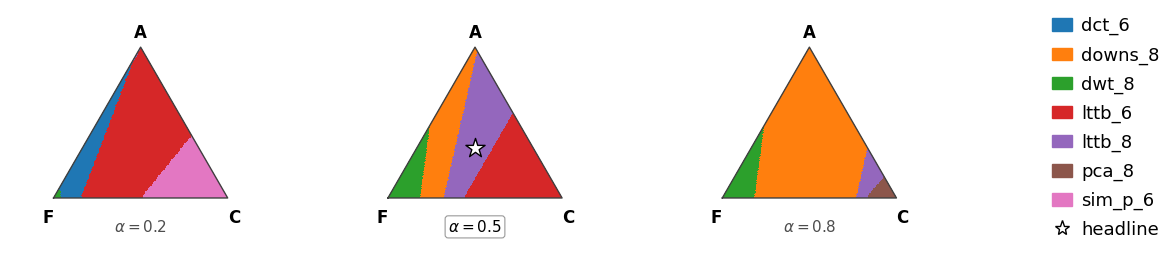

hydraulic

[hydraulic] F-table (32, 4)  task_labels=['forecasting', 'classification', 'aggregate_query', 'storage']
[hydraulic] Pareto-optimal compressors (20/32): ['ae_cr8', 'dct_cr2', 'dct_cr3', 'dct_cr4', 'dct_cr6', 'dct_cr8', 'downsample_cr6', 'downsample_cr8', 'dwt_cr2', 'lttb_cr3', 'lttb_cr4', 'lttb_cr8', 'pca_cr2', 'pca_cr3', 'pca_cr6', 'sim_piece_cr2', 'sim_piece_cr3', 'sim_piece_cr4', 'sim_piece_cr6', 'sim_piece_cr8']


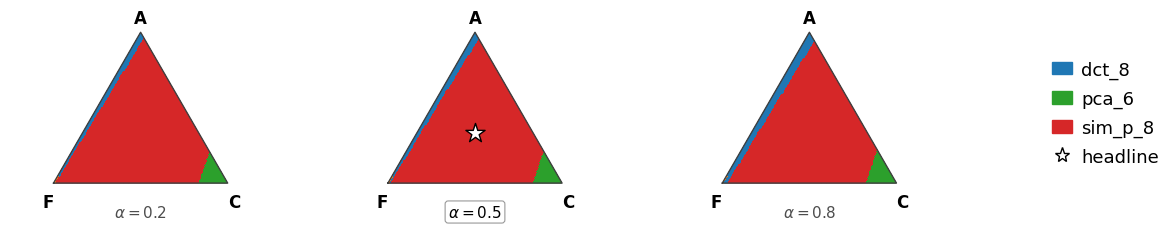

beijing

[beijing] F-table (33, 4)  task_labels=['forecasting', 'classification', 'aggregate_query', 'storage']
[beijing] Pareto-optimal compressors (21/33): ['dct_cr2', 'dct_cr3', 'dct_cr4', 'dct_cr6', 'dct_cr8', 'downsample_cr2', 'downsample_cr3', 'downsample_cr4', 'downsample_cr6', 'downsample_cr8', 'lttb_cr2', 'lttb_cr3', 'lttb_cr4', 'lttb_cr6', 'lttb_cr8', 'pca_cr2', 'pca_cr8', 'sim_piece_cr2', 'sim_piece_cr3', 'sim_piece_cr4', 'sim_piece_cr6']


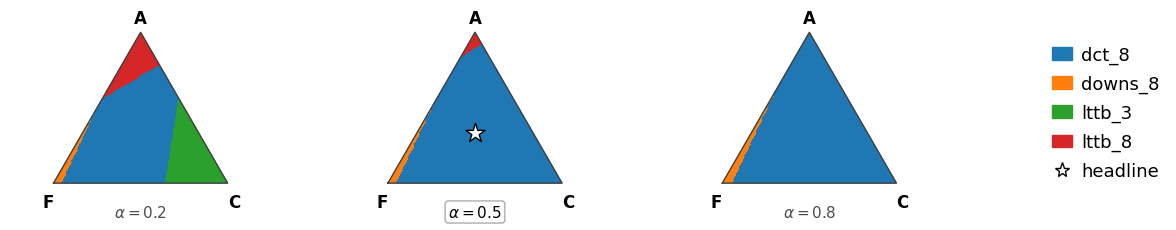

metro

[metro] F-table (30, 4)  task_labels=['forecasting', 'classification', 'aggregate_query', 'storage']
[metro] Pareto-optimal compressors (7/30): ['pca_cr2', 'pca_cr4', 'sim_piece_cr2', 'sim_piece_cr3', 'sim_piece_cr4', 'sim_piece_cr6', 'sim_piece_cr8']


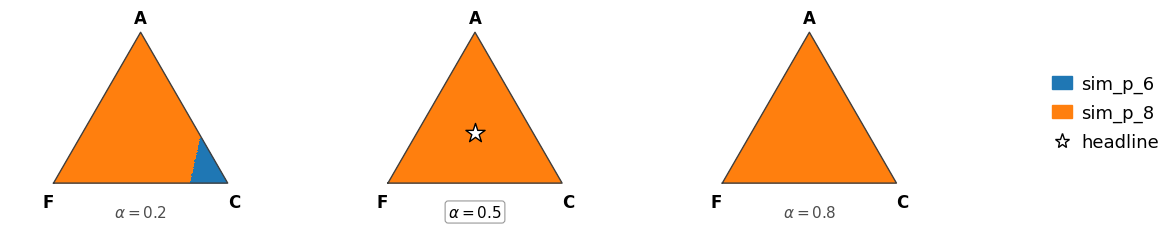

In [12]:
# build F-table from summary_df and plot policy.
from matplotlib.patches import Polygon as _MplPolygon
from matplotlib.colors import ListedColormap as _ListedColormap


def build_F_table(sdf, dataset, df_full=None, storage_col="storage_tilde"):
    """
    Returns:
        F_table      : (K, M) array of [fcst, cls, agg(, past), storage] means
        method_names : (K,) ordered method labels
        task_labels  : (M,) column labels; forecasting vertex includes past

    The three triangle vertices are (forecasting+past), classification,
    and aggregate_query. 
    """
    d = sdf[sdf["dataset"] == dataset].copy()
    diag = [t for t in ["forecasting", "classification", "aggregate_query"]
            if t in d["task"].unique()]
    # Restrict every family (and storage) to the folds where the `past`
    # family is defined.
    past_folds = None
    if df_full is not None:
        pr = past_records(df_full[df_full["dataset"] == dataset],
                          value_col="loss_tilde")
        if not pr.empty:
            past_folds = sorted(pr["fold"].unique())
            d = d[d["fold"].isin(past_folds)]
    per_task = (d.groupby(["task", "method"])["loss_tilde"]
                  .mean().unstack("task"))[diag]
    if past_folds is not None:
        past_h = (pr[pr["fold"].isin(past_folds)]
                  .groupby("method")["loss_tilde"].mean())
        # fold past into the forecasting vertex (equal weight)
        per_task = per_task.join(past_h.rename("past"), how="inner")
        per_task["forecasting"] = per_task[["forecasting", "past"]].mean(axis=1)
        per_task = per_task.drop(columns=["past"])
    task_families = ["forecasting", "classification", "aggregate_query"]
    task_families = [t for t in task_families if t in per_task.columns]
    storage = d.groupby("method")[storage_col].mean()
    methods = sorted(set(per_task.dropna().index) & set(storage.index))
    per_task = per_task.loc[methods, task_families]
    storage = storage.loc[methods]
    F = np.column_stack([per_task.values, storage.values.reshape(-1, 1)])
    return F, methods, task_families + ["storage"]


def _ternary_vertex_labels(ax, task_labels, color="black"):
    """Place the 3 task labels at the 3 vertices of the unit simplex
    triangle (bottom-left, bottom-right, top). Explicit xlim/ylim keep
    `axis('off')` + `tight_layout` from cropping them."""
    h = np.sqrt(3) / 2
    _ABBR = {"forecasting": "F", "classification": "C", "aggregate_query": "A"}
    _lab = [_ABBR.get(t, str(t)[:1].upper()) for t in task_labels]
    for (vx, vy, ha, va, lbl) in [
        (0.0, -0.06, "right",  "top",    _lab[0]),
        (1.0, -0.06, "left",   "top",    _lab[1]),
        (0.5, h + 0.03, "center", "bottom", _lab[2]),
    ]:
        ax.text(vx, vy, lbl, ha=ha, va=va, fontsize=12, fontweight="bold", color=color)
    ax.set_xlim(-0.25, 1.25)
    ax.set_ylim(-0.17, h + 0.09)


def _clip_to_triangle(ax, artist):
    """Clip an axes artist to the unit-simplex triangle so colour fills
    don't bleed past the triangle edges into the axes bounding box."""
    h = np.sqrt(3) / 2
    clip = _MplPolygon([(0, 0), (1, 0), (0.5, h)], closed=True,
                       transform=ax.transData,
                       facecolor="none", edgecolor="none")
    ax.add_patch(clip)
    artist.set_clip_path(clip)


def _categorical_cmap(K):
    """Distinct colours for up to 60 categorical classes by concatenating
    tab20 + tab20b + tab20c. tab20 alone (20 colours) collides on adjacent
    method indices when K > 20."""
    colors = np.vstack([
        plt.cm.tab20.colors,
        plt.cm.tab20b.colors,
        plt.cm.tab20c.colors,
    ])
    if K > len(colors):
        extra = plt.cm.hsv(np.linspace(0, 1, K - len(colors), endpoint=False))
        colors = np.vstack([colors, extra[:, :3]])
    return _ListedColormap(colors[:K])


def _mark_headline(ax):
    """White star at the headline operating point (uniform mu over the
    three task types = triangle centroid)."""
    a, b, cc = MU_HEADLINE_MERGED
    x = b + cc / 2.0
    y = (np.sqrt(3) / 2) * cc
    ax.scatter([x], [y], marker="*", s=210, c="white",
               edgecolors="black", linewidths=1.0, zorder=6)


def plot_policy_M4(F_table, method_names, task_labels,
                   alphas=(0.2, 0.5, 0.8), n=140, min_frac=0.005):
    """Policy regions on the mu-simplex, one panel per alpha. Crisp
    solid winner regions (a dense square-marker scatter, no gouraud
    blending), a clean qualitative palette keyed to the methods that
    actually win, a white star at the headline operating point.
    Only methods covering >= min_frac of any single panel enter the
    legend."""
    from collections import Counter
    panels = [policy_ternary_M4(F_table, a, n=n) for a in alphas]
    panel_pts = max(len(ws) for _, ws, _ in panels)
    min_count = max(1, int(min_frac * panel_pts))
    # best-panel share -> which winners to show in the legend
    max_count = Counter()
    for _, ws, _ in panels:
        for i2, c2 in Counter(int(w) for w in ws.tolist()).items():
            max_count[i2] = max(max_count[i2], c2)
    all_winners = sorted(max_count)
    winners_used = [i2 for i2 in all_winners if max_count[i2] >= min_count]
    # clean qualitative palette keyed to the winning methods only
    base = list(plt.cm.tab10.colors) + list(plt.cm.Set2.colors)
    color_of = {w: base[k % len(base)] for k, w in enumerate(all_winners)}

    ncols = 1 if len(alphas) == 1 else min(3, len(alphas))
    nrows = int(np.ceil(len(alphas) / ncols))
    pw = 4
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(pw * ncols, pw * 0.80 * nrows),
                             squeeze=False,
                             gridspec_kw={"wspace": 0.28, "hspace": 0.0})
    axes_flat = axes.flatten()
    s_marker = max(10.0, (pw * 72 / n) ** 2 * 2.0)
    h_tri = np.sqrt(3) / 2
    for ax, a, (pts, winners, _) in zip(axes_flat, alphas, panels):
        pts = pts / n
        cols = [color_of[int(w)] for w in winners]
        sc = ax.scatter(pts[:, 0], pts[:, 1], c=cols, s=s_marker,
                        marker="s", linewidths=0)
        _clip_to_triangle(ax, sc)
        ax.plot([0, 1, 0.5, 0], [0, 0, h_tri, 0], "-", color="0.25", lw=1.0)
        _ternary_vertex_labels(ax, task_labels)
        # Per-panel storage-weight label (a panel identifier, not a title).
        is_headline = abs(a - 0.5) < 1e-9
        ax.text(0.5, -0.12, rf"$\alpha = {a:.1f}$",
                ha="center", va="top", fontsize=11,
                fontweight="bold" if is_headline else "normal",
                color="black" if is_headline else "0.30",
                bbox=dict(boxstyle="round,pad=0.2", fc="white",
                          ec="0.6" if is_headline else "none", lw=0.8))
        if is_headline:
            _mark_headline(ax)
        ax.set_aspect("equal"); ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=color_of[i2])
               for i2 in winners_used]
    def _abbr(m):
        return (str(m).replace("_cr", "_").replace("sim_piece", "sim_p")
                .replace("downsample", "downs"))
    labels = [_abbr(method_names[i2]) for i2 in winners_used]
    star = plt.Line2D([0], [0], marker="*", color="w", markerfacecolor="w",
                      markeredgecolor="black", markersize=11, linewidth=0,
                      label="headline")
    
        
    fig.legend(handles + [star],
                labels + [star.get_label()],
                loc="center left",
                 bbox_to_anchor=(0.98, 0.5),
                frameon=False,
                fontsize=13,
                handlelength=1.1,
                handletextpad=0.5,
                columnspacing=1.0,
            labelspacing=0.6,)
    for ax in axes_flat[len(alphas):]:
        ax.axis("off")
    fig.tight_layout()
    return fig


# --- Run per dataset --------------------------------------------------------
for ds in DATASETS:
    print(ds)
    if ds not in summary_df["dataset"].unique():
        print(f"[{ds}] not in summary_df — skipped")
        continue
    _lossy = summary_df[~summary_df["method"].isin(LOSSLESS_METHODS)]
    _lossy_full = summary_df_full[~summary_df_full["method"].isin(LOSSLESS_METHODS)]
    F, methods, task_labels = build_F_table(_lossy, ds, df_full=_lossy_full)
    K, M = F.shape
    print(f"\n[{ds}] F-table {F.shape}  task_labels={task_labels}")
    front = pareto_front_indices(F)
    print(f"[{ds}] Pareto-optimal compressors ({len(front)}/{K}): "
          f"{[methods[i] for i in front]}")
    if M != 4:
        print(f"[{ds}] M={M} (task_labels={task_labels}); the ternary sweep "
              f"needs the merged 3-family triangle (3 tasks + storage). "
              f"Skipping plots for this dataset.")
        continue
    fig = plot_policy_M4(F, methods, task_labels[:3])
    fig.savefig(FIGDIR / f"policy_triangle_{ds}.png", dpi=200, bbox_inches="tight")
    plt.show()
